# 1.5 Transfer learning: is this document a CV?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jauniusc/cvmatch/blob/main/1.5/1_5_transfer_learning_documents.ipynb)

Task 1.5 (part 2). Based on the lecturer's **transfer learning notebook** (A. Laukaitis), which uses a pretrained EfficientNetV2 on CIFAR-10.
First I explain how the original works, then I redo it with my **CV / document dataset** from task 1.4, so I can compare it with my own CNN.

## How the original notebook works

**Transfer learning** = take a model that was already trained on a huge dataset (ImageNet) and reuse what it learned for a new task.
The early layers already know edges, textures and shapes, so we only need to train a small new part on top.

**Chapter 1. Train a new classifier on top of a frozen model**
1. Loads CIFAR-10 (32×32 images, 10 classes) from Hugging Face and divides the pixels by 255.
2. Downloads **EfficientNetV2-B1** (trained on ImageNet-21k) from TF Hub as a **feature vector** model:
   it doesn't give classes, it gives 1,280 numbers that describe the image.
   It is wrapped in `hub.KerasLayer(..., trainable=False)`, so its ~6.9 million weights are **frozen** (not changed during training).
3. `hub.KerasLayer` works with Keras 2, so the notebook installs and uses **`tf_keras`** instead of the new Keras 3.
4. The model is: `Resizing(240, 240)` (the 32×32 images are scaled up to the size EfficientNet expects) → EfficientNet → `Dense(10)`.
   Only the last layer is trained: 1,280 × 10 + 10 = **12,810 trainable parameters**.
5. After only **3 epochs** test accuracy is **~88.5%**, much better than the ~70% of the CNN trained from zero in task 1.4.
6. Saves the model (SavedModel format, zipped) and shows 100 test images with true/predicted labels (green = correct, red = wrong).

**Chapter 2. Data augmentation and fine-tuning**
7. Loads the saved model again, makes the learning rate 10× smaller (0.001 → 0.0001) and sets `model.trainable = True`,
   so the EfficientNet weights could also change (**fine-tuning**). A small learning rate is needed so the pretrained weights are not destroyed.
8. **Data augmentation:** random horizontal flip, rotation, brightness and shift. In every iteration a new randomly changed copy
   of the training set is made and the model is trained 1 epoch on it (3 iterations). This makes the model see "new" images and overfit less.
9. Result: validation accuracy ~**87.6%**, about the same as before augmentation.

## My data: CVs and other documents

The same dataset as in task 1.4: scanned documents 128×128 in 4 classes (`resume`, `letter`, `email`, `form`),
700 / 150 / 150 images per class for train / validation / test (from RVL-CDIP, see `data/documents/`).

EfficientNet was trained on photos (animals, cars, food...), not on documents, so it is interesting to see if its features still help here.

What I changed: the data loading, 4 classes, validation data separate from test, a smaller batch size for fine-tuning
and BatchNorm kept in inference mode during fine-tuning. The model and the training steps are the same as in the original.

In [1]:
%pip install -q tf_keras

Note: you may need to restart the kernel to use updated packages.


In [2]:
import tensorflow as tf
import tensorflow_hub as hub
import tf_keras
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)

---
# Chapter 1. Create the model, train it and save it
### Step 1. Load my document dataset

In [3]:
import os
import numpy as np
from PIL import Image

# Locally the images are in the repo. In Colab the repo is cloned first.
if os.path.exists('../data/documents'):
  data_dir = '../data/documents'
else:
  !git clone -q https://github.com/jauniusc/cvmatch.git
  data_dir = 'cvmatch/data/documents'

class_names = ['resume', 'letter', 'email', 'form']

def load_folder(split):
  images, labels = [], []
  for label, name in enumerate(class_names):
    folder = os.path.join(data_dir, split, name)
    for file in sorted(os.listdir(folder)):
      img = Image.open(os.path.join(folder, file)).convert('RGB')   # greyscale scan -> 3 channels
      images.append(np.array(img))
      labels.append(label)
  images = np.array(images).astype('float32') / 255.0   # normalize to 0..1
  labels = np.array(labels).reshape(-1, 1)
  order = np.random.RandomState(42).permutation(len(images))   # the files are sorted by class, so shuffle them
  return images[order], labels[order]

train_images, train_labels = load_folder('train')
val_images, val_labels = load_folder('val')
test_images, test_labels = load_folder('test')

print(train_images.shape, val_images.shape, test_images.shape)
print('Images per class (train):', np.bincount(train_labels[:, 0]))

(2800, 128, 128, 3) (600, 128, 128, 3) (600, 128, 128, 3)
Images per class (train): [700 700 700 700]


### Step 2. Model: frozen EfficientNetV2-B1 + new Dense layer

In [4]:
feature_extractor_model = "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_b1/feature_vector/2"
IMAGE_SHAPE = (240, 240)
feature_extractor_layer = hub.KerasLayer(feature_extractor_model,
                                         input_shape=(IMAGE_SHAPE[0], IMAGE_SHAPE[1], 3),
                                         trainable=False)

num_classes = len(class_names)
resize = tf_keras.layers.Resizing(IMAGE_SHAPE[0], IMAGE_SHAPE[1])

model = tf_keras.Sequential([resize, feature_extractor_layer, tf_keras.layers.Dense(num_classes)])
model.compile(optimizer='adam',
              loss=tf_keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

model.build(input_shape=(None, 128, 128, 3))
model.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 resizing (Resizing)         (None, 240, 240, 3)       0         


 keras_layer (KerasLayer)    (None, 1280)              6931124   


 dense (Dense)               (None, 4)                 5124      


Total params: 6936248 (26.46 MB)


Trainable params: 5124 (20.02 KB)


Non-trainable params: 6931124 (26.44 MB)


_________________________________________________________________


Only 1,280 × 4 + 4 = **5,124** parameters are trained, compared to ~3.3 million in my CNN from task 1.4.

### Step 3. Train (only the last layer)

In [5]:
history = model.fit(train_images, train_labels, epochs=3, validation_data=(val_images, val_labels), verbose=2)

Epoch 1/3


88/88 - 56s - loss: 0.8988 - accuracy: 0.6389 - val_loss: 0.6437 - val_accuracy: 0.7917 - 56s/epoch - 639ms/step


Epoch 2/3


88/88 - 63s - loss: 0.6039 - accuracy: 0.7843 - val_loss: 0.5783 - val_accuracy: 0.7967 - 63s/epoch - 712ms/step


Epoch 3/3


88/88 - 56s - loss: 0.5213 - accuracy: 0.8239 - val_loss: 0.5087 - val_accuracy: 0.8417 - 56s/epoch - 642ms/step


In [6]:
test_loss, frozen_test_acc = model.evaluate(test_images, test_labels, verbose=2)
print("Test accuracy (frozen EfficientNet):", frozen_test_acc)

19/19 - 10s - loss: 0.4738 - accuracy: 0.8550 - 10s/epoch - 504ms/step


Test accuracy (frozen EfficientNet): 0.8550000190734863


### Save the model

In [7]:
export_path = "saved_model_documents"
model.save(export_path)

INFO:tensorflow:Assets written to: saved_model_documents/assets


INFO:tensorflow:Assets written to: saved_model_documents/assets


### Let's plot 50 test images with predictions
Green = correct, red = wrong (true / predicted). I predict all images in one call instead of a loop, it is faster.

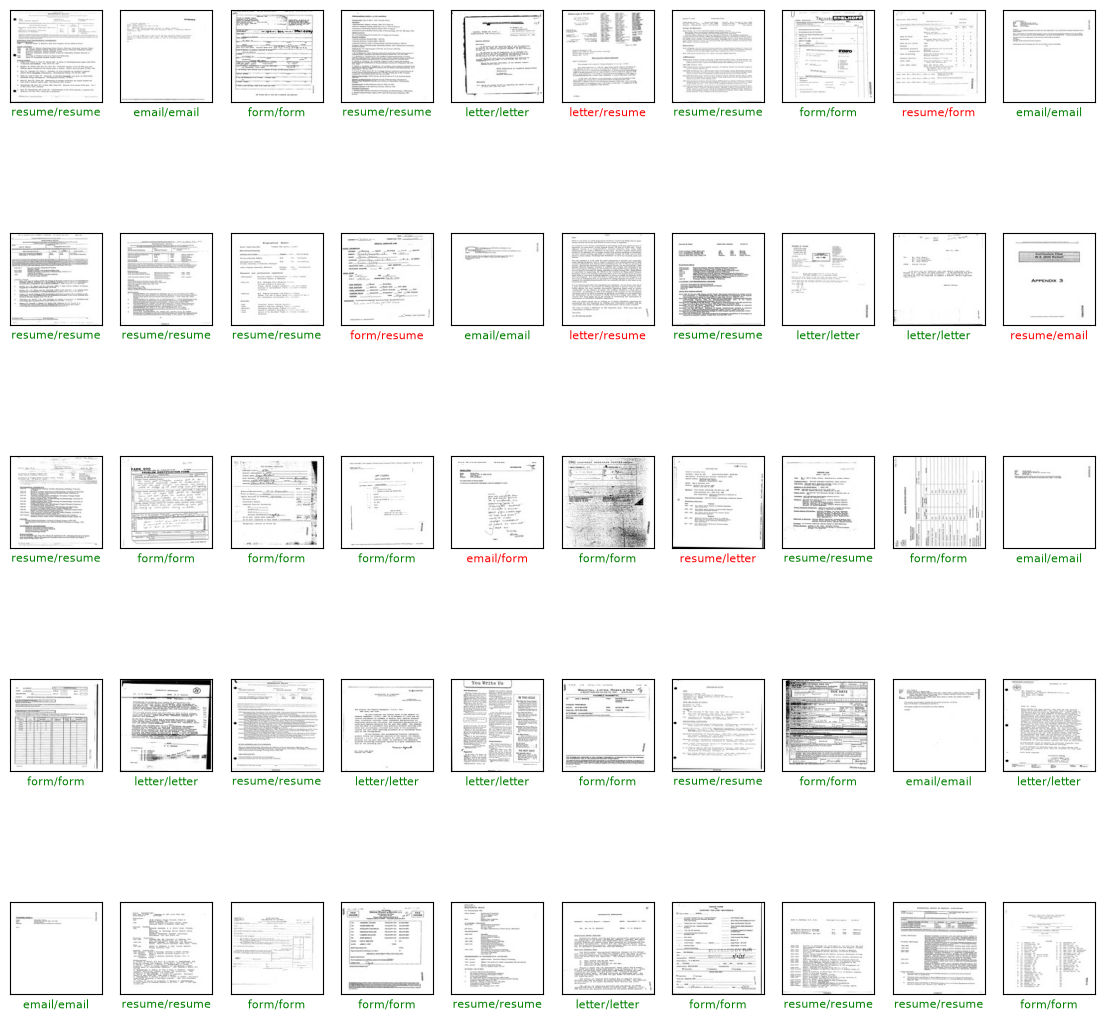

In [8]:
result = model.predict(test_images[:50], verbose=0)
predicted_class_name = [class_names[i] for i in np.argmax(result, axis=1)]

plt.figure(figsize=(14, 14))
for i in range(50):
  plt.subplot(5, 10, i + 1)
  plt.xticks([]); plt.yticks([]); plt.grid(False)
  plt.imshow(test_images[i])
  true_name = class_names[test_labels[i][0]]
  color = 'green' if true_name == predicted_class_name[i] else 'red'
  plt.xlabel(true_name + '/' + predicted_class_name[i], color=color, fontsize=8)
plt.show()

---
# Chapter 2. Data augmentation and fine-tuning
### Load the saved model

In [9]:
model = tf_keras.models.load_model(export_path, custom_objects={'KerasLayer': hub.KerasLayer})

for layer in model.layers:
  print(f"Layer: {layer.name}, Trainable: {layer.trainable}")

Layer: resizing, Trainable: True
Layer: keras_layer, Trainable: False
Layer: dense, Trainable: True


### Unfreeze EfficientNet and compile again with a small learning rate
I use 0.00001: the original used 0.0001, but when the whole network is trained a smaller step is safer for the pretrained weights.

EfficientNet has many **BatchNormalization** layers that normalize the data with the mean and variance learned on ImageNet.
As the Keras transfer learning guide recommends, I keep them in **inference mode** while fine-tuning:
I rebuild the same 3 layers as a functional model and call EfficientNet with `training=False`.
Its weights are still trained, but BatchNorm keeps the ImageNet statistics, so the features don't suddenly change.

In [10]:
resize_layer, base_layer, dense_layer = model.layers
base_layer.trainable = True

inputs = tf_keras.Input(shape=(128, 128, 3))
x = resize_layer(inputs)
x = base_layer(x, training=False)   # BatchNorm stays in inference mode
outputs = dense_layer(x)
model = tf_keras.Model(inputs, outputs)

model.compile(optimizer=tf_keras.optimizers.Adam(learning_rate=1e-5),
              loss=tf_keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

for layer in model.layers:
  print(f"Layer: {layer.name}, Trainable: {layer.trainable}")
print("Trainable weights:", sum(np.prod(w.shape) for w in model.trainable_weights))

Layer: input_1, Trainable: True
Layer: resizing, Trainable: True
Layer: keras_layer, Trainable: True
Layer: dense, Trainable: True
Trainable weights: 6865176


### Data augmentation
The same layers as the original, but **without the horizontal flip**: a mirrored document doesn't look like a real document
(the text would be on the wrong side), so for my data it would teach the model wrong things.

In [11]:
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomRotation(0.02),
  tf.keras.layers.RandomBrightness(factor=0.1, value_range=(0, 1)),
  tf.keras.layers.RandomTranslation(0.05, 0.05),
])

I also made the rotation (0.02 instead of 0.1) and the shift (5% instead of 10%) smaller, because scanned pages are usually almost straight.

### Fine-tune: every iteration = new augmented copy of the training set, 1 epoch
I use batch size 32 (the original used 64) because training the whole EfficientNet needs much more memory.

In [12]:
for i in range(3):
  print(f"--- Iteration {i+1}/3 ---")
  augmented_train_images = data_augmentation(train_images)
  history = model.fit(augmented_train_images, train_labels, epochs=1, batch_size=32,
                      validation_data=(val_images, val_labels), verbose=2)

--- Iteration 1/3 ---


88/88 - 274s - loss: 0.5579 - accuracy: 0.8071 - val_loss: 0.5654 - val_accuracy: 0.7950 - 274s/epoch - 3s/step


--- Iteration 2/3 ---


88/88 - 247s - loss: 0.4759 - accuracy: 0.8386 - val_loss: 0.5002 - val_accuracy: 0.8233 - 247s/epoch - 3s/step


--- Iteration 3/3 ---


88/88 - 267s - loss: 0.4323 - accuracy: 0.8479 - val_loss: 0.4826 - val_accuracy: 0.8317 - 267s/epoch - 3s/step


In [13]:
test_loss, finetuned_test_acc = model.evaluate(test_images, test_labels, verbose=2)
print("Test accuracy (frozen EfficientNet):    ", frozen_test_acc)
print("Test accuracy (fine-tuned + augmented): ", finetuned_test_acc)

predictions = np.argmax(model.predict(test_images, verbose=0), axis=1)
print("CV vs not-CV accuracy:", np.mean((test_labels[:, 0] == 0) == (predictions == 0)))

19/19 - 10s - loss: 0.4223 - accuracy: 0.8467 - 10s/epoch - 538ms/step


Test accuracy (frozen EfficientNet):     0.8550000190734863
Test accuracy (fine-tuned + augmented):  0.846666693687439


CV vs not-CV accuracy: 0.9283333333333333


---
## Results and conclusions

| Model | Trained parameters | Test accuracy |
|---|---|---|
| My CNN from zero (task 1.4) | 3,267,908 | 0.813 |
| **Frozen EfficientNetV2-B1 + new Dense layer** | **5,124** | **0.855** |
| Fine-tuned + augmentation | 6,865,176 | 0.847 |

- Transfer learning beats my own CNN while training only 5,124 parameters for 3 epochs.
  EfficientNet was trained on photos, not documents, but its features are still useful here.
- It also overfits less: after 3 epochs train accuracy is 0.82 and validation 0.84 (my CNN had 100% on train).
- Fine-tuning didn't improve the result, like in the original notebook. With a small learning rate and only 3 iterations the weights change very little,
  and on my laptop CPU every iteration takes ~4–5 minutes.
- For CVMatch: the model answers "CV or not CV?" correctly for **92.8%** of the test scans.